<a href="https://colab.research.google.com/github/Aisyaaswy/Pemrograman_Mesin/blob/main/jobsheet_7/dataset_pbl/praktikum_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Praktikum 1**
## **Langkah 1: Persiapan Data**
Download dan letakkan file data yang akan digunakan pada direktori yang sama. Pastikan data telah disimpan dalam format CSV.

## **Langkah 2: Import Library**

In [ ]:
# import package
import numpy as np
import pandas as pd

Import library NumPy dan Pandas yang digunakan untuk manipulasi data.

## **Langkah 3: Baca Data**

In [ ]:
# baca data dari file CSV
data = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')

Baca data dari file CSV dengan menggunakan Pandas.

## **Langkah 4: Pemahaman Terhadap Data**

In [ ]:
# melihat beberapa data awal
data.head()

# mengecek ukuran data
data.shape

# informasi tentang data
data.info()

# deskripsi data
data.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB


,Person ID,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps
count,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000
mean,187.500000,42.184492,7.132086,7.312834,59.171123,5.385027,70.165775,6816.844920
std,108.108742,8.673133,0.795657,1.196956,20.830804,1.774526,4.135676,1617.915679
min,1.000000,27.000000,5.800000,4.000000,30.000000,3.000000,65.000000,3000.000000
25%,94.250000,35.250000,6.400000,6.000000,45.000000,4.000000,68.000000,5600.000000
50%,187.500000,43.000000,7.200000,7.000000,60.000000,5.000000,70.000000,7000.000000
75%,280.750000,50.000000,7.800000,8.000000,75.000000,7.000000,72.000000,8000.000000
max,374.000000,59.000000,8.500000,9.000000,90.000000,8.000000,86.000000,10000.000000


Tampilkan beberapa data awal, ukuran data, informasi data, dan deskripsi statistik data untuk memahami karakteristik data.

## **Langkah 5: Visualisasi Data**

In [ ]:
# import library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

Import library Matplotlib dan Seaborn untuk visualisasi data.

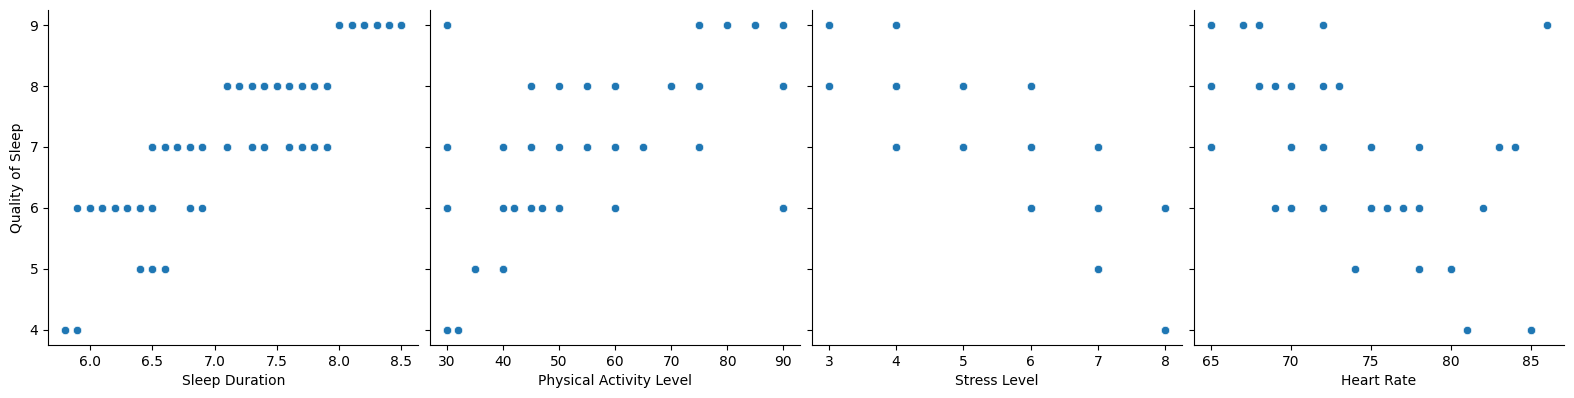

In [ ]:
# Pairplot fitur numerik utama terhadap Quality of Sleep
sns.pairplot(
    data,
    x_vars=['Sleep Duration', 'Physical Activity Level', 'Stress Level', 'Heart Rate'],
    y_vars='Quality of Sleep',
    height=4,
    aspect=1,
    kind='scatter'
)
plt.show()

Gunakan pairplot untuk menampilkan hubungan antara variabel bebas dan variabel target dalam bentuk scatter plot.

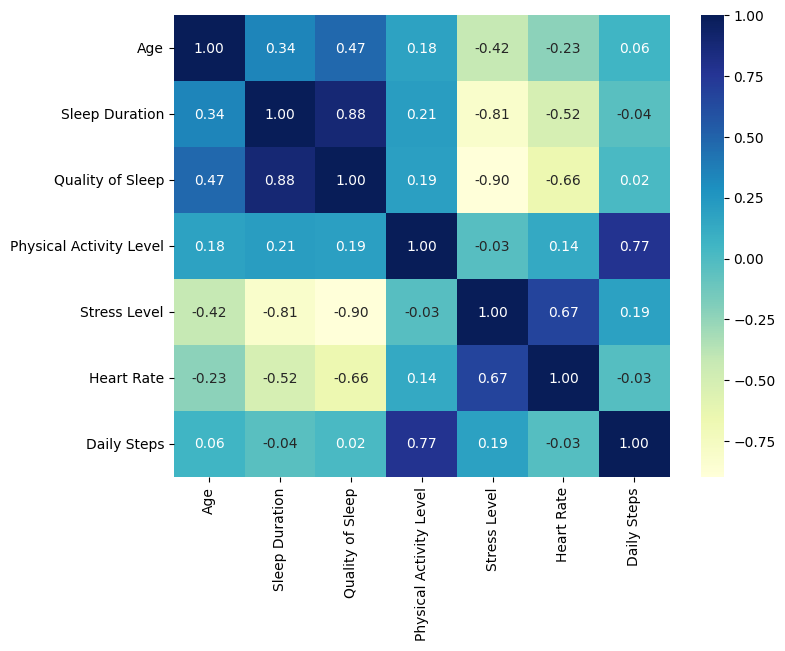

In [ ]:
# Heatmap korelasi khusus kolom numerik (mengecualikan Person ID)
numeric_data = data.select_dtypes(include=['float64', 'int64']).drop(columns=['Person ID'], errors='ignore')
plt.figure(figsize=(8, 6))
sns.heatmap(numeric_data.corr(), cmap="YlGnBu", annot=True, fmt=".2f")
plt.show()

## **Langkah 6: Regresi Linear**

In [ ]:
from sklearn.model_selection import train_test_split
import statsmodels.api as sm

In [ ]:
# Membuat variabel bebas X dan Y, contoh pengambilan dari analisis korelasi sebelumnya
X = data['Sleep Duration']
y = data['Quality of Sleep']

Pisahkan variabel bebas (X) dan variabel target (y).

In [ ]:
# Pembagian data latih dan data uji dengan proporsi 7:3
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, test_size=0.3, random_state=100
)

- Bagi data menjadi data latih (70%) dan data uji (30%) menggunakan train_test_split.

- Lakukan training model regresi linier menggunakan library StatsModels. Tambahkan konstanta (intercept) ke variabel bebas.

In [ ]:
# Training model
X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()

print(lr.summary())

                            OLS Regression Results                            
Dep. Variable:       Quality of Sleep   R-squared:                       0.800
Model:                            OLS   Adj. R-squared:                  0.799
Method:                 Least Squares   F-statistic:                     1033.
Date:                Wed, 18 Nov 2026   Prob (F-statistic):           2.18e-92
Time:                        02:45:19   Log-Likelihood:                -200.70
No. Observations:                 261   AIC:                             405.4
Df Residuals:                     259   BIC:                             412.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const             -1.9580      0.290     -6.

Visualisasikan garis regresi pada data latih.

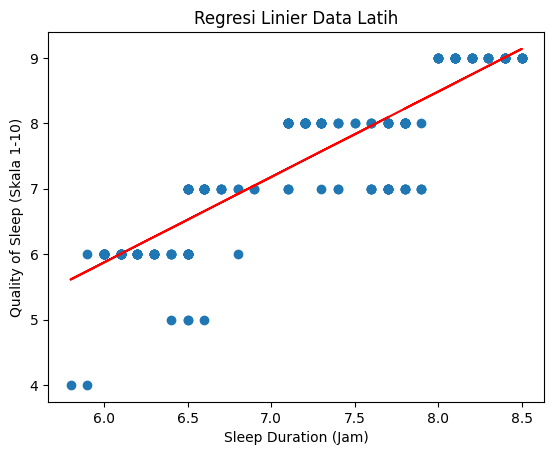

In [ ]:
# Visualisasi garis regresi
plt.scatter(X_train, y_train)
plt.plot(X_train, lr.predict(X_train_sm), 'r')
plt.xlabel('Sleep Duration (Jam)')
plt.ylabel('Quality of Sleep (Skala 1-10)')
plt.title('Regresi Linier Data Latih')
plt.show()

## **Langkah 7: Analisis Residual**

In [ ]:
# Prediksi nilai y_value dari data x yang telah dilatih
y_train_pred = lr.predict(X_train_sm)

# Menghitung residual
res = (y_train - y_train_pred)


Lakukan prediksi nilai y dari data latih dan hitung residual (selisih antara nilai sebenarnya dan nilai prediksi).

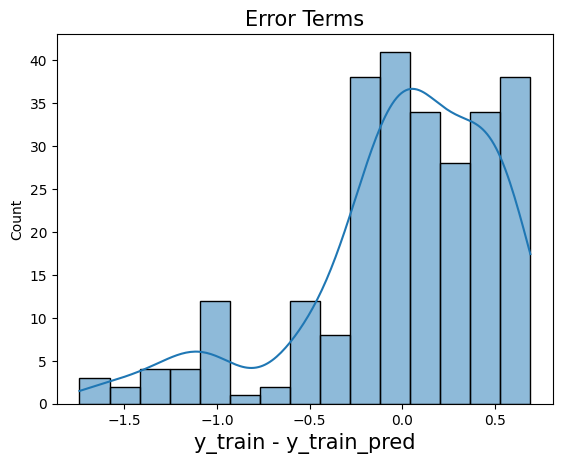

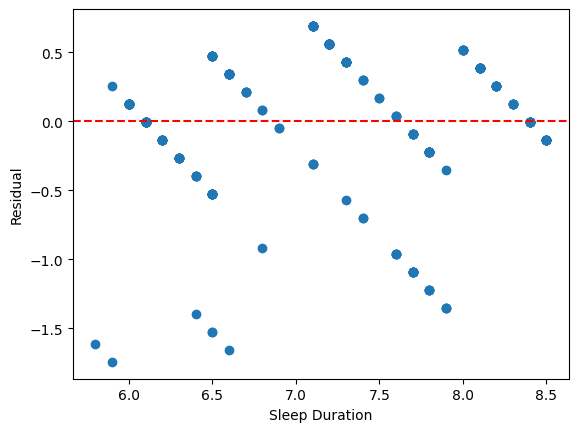

In [ ]:
# Histogram distribusi residual (menggunakan histplot menggantikan distplot)
plt.figure()
sns.histplot(res, bins=15, kde=True)
plt.title('Error Terms', fontsize=15)
plt.xlabel('y_train - y_train_pred', fontsize=15)
plt.show()

# Scatter plot residual
plt.scatter(X_train, res)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Sleep Duration')
plt.ylabel('Residual')
plt.show()

Visualisasikan residual dalam bentuk histogram dan scatter plot untuk mengevaluasi distribusi dan pola error.

## **Langkah 8: Prediksi pada Data Uji dan Evaluasi Model**

In [ ]:
# Prediksi pada data uji
X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)

Lakukan prediksi pada data uji.

In [ ]:
# Hitung nilai R-squared
from sklearn.metrics import r2_score

r_squared = r2_score(y_test, y_test_pred)

print(f"Nilai R-squared pada data uji: {r_squared:.4f}")

Nilai R-squared pada data uji: 0.7376



Hitung nilai R-squared untuk mengukur kinerja model pada data uji.

## **Langkah 9: Visualisasi Hasil**

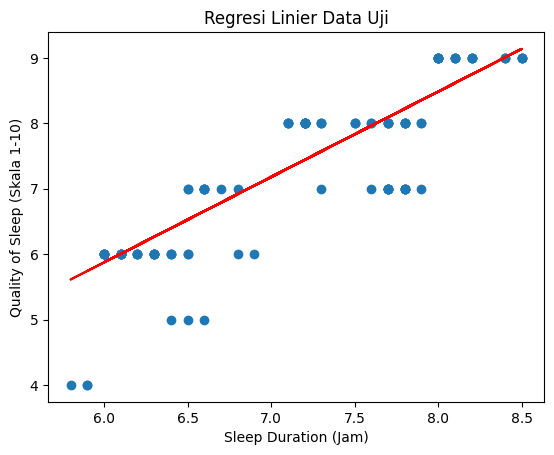

In [ ]:
# Visualisasi data uji dan hasil prediksi
plt.scatter(X_test, y_test)
plt.plot(X_test, y_test_pred, 'r')
plt.xlabel('Sleep Duration (Jam)')
plt.ylabel('Quality of Sleep (Skala 1-10)')
plt.title('Regresi Linier Data Uji')
plt.show()

Visualisasikan data uji dan hasil prediksi dalam bentuk scatter plot.
